# FinSight — Exploratory Data Analysis of Financial PhraseBank (`sentences_50agree`)

**Goal:** understand the data *before* modelling. Each section states what was investigated, then shows results, then an **Interpretation** block: *what the data revealed, why it matters, and what it implies for modelling*.

**Reproduce:** `venv\python.exe -m src.data` (download) → run all cells. Everything is seeded; figures are written to `analysis/figures/`.

| Section | Topic |
|---|---|
| A | Dataset understanding & integrity |
| B | Sentiment distribution & imbalance |
| C | Text length |
| D | Linguistic analysis |
| E | Class-wise linguistic analysis |
| F | Financial vocabulary |
| G | Data quality & outliers |
| H | Annotator agreement |
| I | Feature representation (TF-IDF) |
| J | Conclusions |

In [1]:
import sys, re, json, warnings, zipfile
from pathlib import Path
from collections import Counter
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
import config
from src import data as D

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import nltk
try:
    from nltk.corpus import stopwords; STOP = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords; STOP = set(stopwords.words("english"))

FIG = ROOT / "analysis" / "figures"; FIG.mkdir(exist_ok=True)
PAPER, CHAR, COPPER, SAGE, GOLD, FOREST, BURG, GRID = "#F2EFE6","#252724","#D97745","#A5B88A","#D6B66C","#34483B","#914D4B","#D9D4C8"
CLS = ["negative", "neutral", "positive"]
CC = {"negative": BURG, "neutral": GOLD, "positive": FOREST}
plt.rcParams.update({"figure.facecolor":PAPER,"axes.facecolor":PAPER,"savefig.facecolor":PAPER,"axes.edgecolor":CHAR,
    "axes.grid":True,"grid.color":GRID,"axes.spines.top":False,"axes.spines.right":False,"font.size":10,
    "axes.titleweight":"bold","axes.titlesize":11})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)

df = pd.read_csv(config.PROCESSED_FILE)          # processed (whitespace-trimmed) data, nothing removed
print("Loaded", config.PROCESSED_FILE.name, df.shape)

Loaded phrasebank_50agree.csv (4846, 3)


## Section A — Dataset understanding
*Investigated:* structure, types, integrity, duplicates, conflicting labels, empty text.

In [2]:
print("Shape (rows, columns):", df.shape)
print("Records:", len(df), "| Features:", df.shape[1], "(sentence = input text, label = target; label_name is a readable copy)")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "n_unique": df.nunique(),
    "description": ["Financial news sentence (tokenised, space-separated punctuation)",
                    "Sentiment class id: 0=negative, 1=neutral, 2=positive",
                    "Readable class name (derived from label)"]}))
print("\nFIRST 3"); display(df.head(3)[["sentence","label_name"]])
print("LAST 3");  display(df.tail(3)[["sentence","label_name"]])
print("RANDOM 8 (seed 42)"); display(df.sample(8, random_state=config.RANDOM_SEED)[["sentence","label_name"]])
print("Unique labels:", sorted(df.label_name.unique()))

Shape (rows, columns): (4846, 3)
Records: 4846 | Features: 3 (sentence = input text, label = target; label_name is a readable copy)


,dtype,missing,n_unique,description
sentence,str,0,4838,"Financial news sentence (tokenised, space-separated punctuation)"
label,int64,0,3,"Sentiment class id: 0=negative, 1=neutral, 2=positive"
label_name,str,0,3,Readable class name (derived from label)



FIRST 3


,sentence,label_name
0,"According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .",neutral
1,"Technopolis plans to develop in stages an area of no less than 100,000 square meters in order to host companies working in computer tech...",neutral
2,The international electronic industry company Elcoteq has laid off tens of employees from its Tallinn facility ; contrary to earlier lay...,negative


LAST 3


,sentence,label_name
4843,"Operating profit fell to EUR 35.4 mn from EUR 68.8 mn in 2007 , including vessel sales gain of EUR 12.3 mn .",negative
4844,"Net sales of the Paper segment decreased to EUR 221.6 mn in the second quarter of 2009 from EUR 241.1 mn in the second quarter of 2008 ,...",negative
4845,"Sales in Finland decreased by 10.5 % in January , while sales outside Finland dropped by 17 % .",negative


RANDOM 8 (seed 42)


,sentence,label_name
3207,"The company was supposed to deliver machinery to a veneer mill in the Tomsk region , in Russia .",neutral
1684,UNC Charlotte would also deploy SSH Tectia Connector to enable secure application connectivity .,neutral
1044,"In 2009 , Lee & Man had a combined annual production capacity of close to 4.5 million tonnes of paper and 300,000 tonnes of pulp .",neutral
4145,"`` That 's a very high figure on the European scale , '' Noop said , recalling however that this also includes beer bought by Finnish to...",neutral
1538,"In Finland , the corresponding service is Alma Media 's Etuovi.com , Finland 's most popular and best known nationwide online service fo...",neutral
1034,Construction is scheduled to start in April-June 2007 and to be completed in early 2008 .,neutral
2107,Finnish-owned contract manufacturer of electronics Elcoteq Hungary Kft has announced plans to recruit more than 650 new staffers to fulf...,positive
4257,"The gross area of the Innova 2 project will be about 10,000 sq m ( 107,600 sq ft ) .",neutral


Unique labels: ['negative', 'neutral', 'positive']


In [3]:
s = df.sentence
dup_groups = df[df.duplicated("sentence", keep=False)].groupby("sentence")["label_name"].agg(list)
conflict = dup_groups[dup_groups.map(lambda l: len(set(l)) > 1)]
mojibake = s.str.contains(r"\+[\xc0-\xff]")
integrity = pd.Series({
    "missing values": int(df.isna().sum().sum()),
    "empty / whitespace-only sentences": int((s.str.strip() == "").sum()),
    "exact duplicate rows (sentence+label)": int(df.duplicated(["sentence","label"]).sum()),
    "extra copies of a repeated sentence": int(df.duplicated("sentence").sum()),
    "distinct sentences repeated": len(dup_groups),
    "sentences with CONFLICTING labels": len(conflict),
    "rows with source-encoding damage ('+ñ'-style)": int(mojibake.sum()),
    "label ids outside {0,1,2}": int((~df.label.isin([0,1,2])).sum()),
})
display(integrity.to_frame("count"))
print("Conflicting-label sentences:"); display(conflict.to_frame("labels"))
print("Encoding-damage examples:"); display(df[mojibake].sentence.head(3).to_frame())
print("Damaged rows by class:", df[mojibake].label_name.value_counts().to_dict())

,count
missing values,0
empty / whitespace-only sentences,0
exact duplicate rows (sentence+label),6
extra copies of a repeated sentence,8
distinct sentences repeated,8
sentences with CONFLICTING labels,2
rows with source-encoding damage ('+ñ'-style),91
"label ids outside {0,1,2}",0


Conflicting-label sentences:


,labels
sentence,
TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sells stake in Morning Digital Design Oy Finnish IT company TJ Group Plc said on Friday 7 April that it had signed an agreement on selling its shares of Morning Digital Design Oy to Edita Oyj .,"[neutral, positive]"
The Group 's business is balanced by its broad portfolio of sports and presence in all major markets .,"[positive, neutral]"


Encoding-damage examples:


,sentence
14,"Clothing retail chain Sepp+ñl+ñ 's sales increased by 8 % to EUR 155.2 mn , and operating profit rose to EUR 31.1 mn from EUR 17.1 mn in..."
30,"The Brazilian unit of Finnish security solutions provider F-Secure signed up 1,500 new clients last year , online news source Reseller W..."
94,Finnish Bank of +àland 's consolidated net operating profit increased from EUR 4.8 mn in the first quarter of 2005 to EUR 6.4 mn in the ...


Damaged rows by class: {'neutral': 53, 'positive': 25, 'negative': 13}


**Interpretation (A) — Dataset understanding**

- **Investigated:** shape, types, integrity, duplicates, conflicting labels, encoding.
- **Revealed:** 4,846 rows × 2 real columns (`sentence`, `label`; `label_name` is a readable copy). No missing values, no empty sentences, labels only in {0,1,2}. Only **4,838 sentences are distinct**: 8 sentences appear twice (6 with the same label both times, **2 with conflicting labels** — e.g. *"The Group's business is balanced by its broad portfolio of sports…"* is both positive and neutral). **91 rows** carry a source-encoding artefact (`Seppälä` → `Sepp+ñl+ñ`); this is in the authors' original file, mostly names, and spread roughly in proportion to class size (53 neutral / 25 positive / 13 negative).
- **Why it matters:** the task is *sentence-level 3-class sentiment classification of financial news*. Duplicates matter because a sentence in both train and test would inflate scores; conflicts matter because they show the labels are not perfectly crisp.
- **Implication:** `src/data.clean()` drops both copies of conflicting sentences and keeps one copy of same-label duplicates (4,846 → **4,836** rows). Encoding artefacts are left alone (see Section G).

## Section B — Sentiment distribution
*Investigated:* class counts, imbalance, and what a do-nothing baseline scores.

,count,percent
label_name,,
negative,604,12.46
neutral,2879,59.41
positive,1363,28.13


Imbalance ratio (majority / minority): 4.77 : 1   (neutral / negative)
Majority-class baseline  accuracy=0.594   macro-F1=0.248


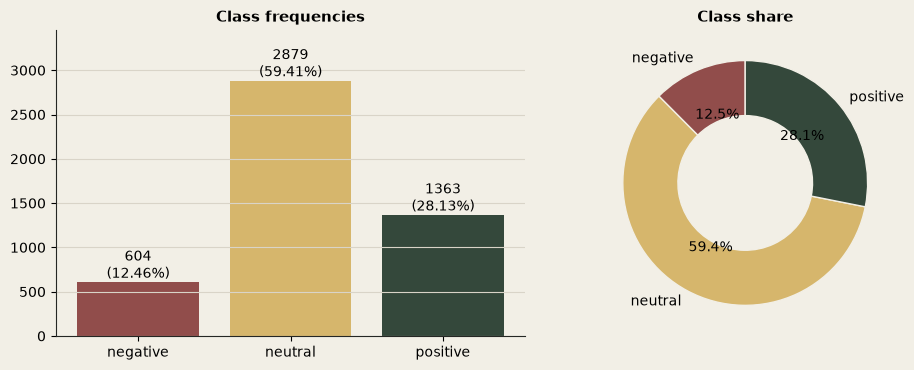

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
cnt = df.label_name.value_counts().reindex(CLS)
pct = (100 * cnt / cnt.sum()).round(2)
display(pd.DataFrame({"count": cnt, "percent": pct}))
print(f"Imbalance ratio (majority / minority): {cnt.max()/cnt.min():.2f} : 1   (neutral / negative)")
dm = DummyClassifier(strategy="most_frequent").fit(df[["sentence"]], df.label)
pred = dm.predict(df[["sentence"]])
print(f"Majority-class baseline  accuracy={accuracy_score(df.label, pred):.3f}   macro-F1={f1_score(df.label, pred, average='macro'):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
bars = ax[0].bar(CLS, cnt.values, color=[CC[c] for c in CLS])
ax[0].bar_label(bars, labels=[f"{n}\n({p}%)" for n, p in zip(cnt.values, pct.values)]); ax[0].set_ylim(0, cnt.max()*1.2)
ax[0].set_title("Class frequencies"); ax[0].grid(axis="x", visible=False)
ax[1].pie(cnt.values, labels=CLS, colors=[CC[c] for c in CLS], autopct="%1.1f%%", startangle=90, wedgeprops=dict(width=0.45, edgecolor=PAPER))
ax[1].set_title("Class share"); fig.tight_layout(); save(fig, "B_class_distribution")

**Interpretation (B) — Sentiment distribution**

- **Investigated:** class frequencies and what a "do nothing" model scores.
- **Revealed:** neutral 2,879 (59.4%), positive 1,363 (28.1%), negative 604 (12.5%). Imbalance ratio neutral:negative = **4.77 : 1**. Always predicting "neutral" gives **accuracy 0.594 but macro-F1 only 0.248**.
- **Why it matters:** with a majority class this large, **accuracy is flattering** — a model can look decent while missing most negative sentences. Precision/recall for the minority classes (especially *negative*) can be poor while overall accuracy stays high. Weighted-F1 is dominated by neutral; **macro-F1 weights the three classes equally** and exposes the minority-class weakness.
- **Implication:** select models by **macro-F1** (as specified), always report per-class precision/recall, and use **stratified splits** (done — class mix is identical in train/val/test). Handling imbalance: try `class_weight="balanced"` for the linear models as a hyper-parameter rather than resampling (resampling text before vectorising risks duplicating sentences across folds). Any accuracy figure must be read against the 0.594 baseline.

## Section C — Text length
*Investigated:* character/word counts overall and per class; whether length separates sentiment.

,n_chars,n_words
mean,128.13,23.10
median,119.00,21.00
min,9.00,2.00
max,315.00,81.00
std,56.53,9.96


,count,mean,median,std,min,max
label_name,,,,,,
negative,604,23.92,22.0,9.89,5,56
neutral,2879,22.18,21.0,9.82,2,81
positive,1363,24.69,23.0,10.06,5,57


Kruskal-Wallis on word count by class: H=64.6, p=9.44e-15, epsilon^2 (effect size)=0.0129


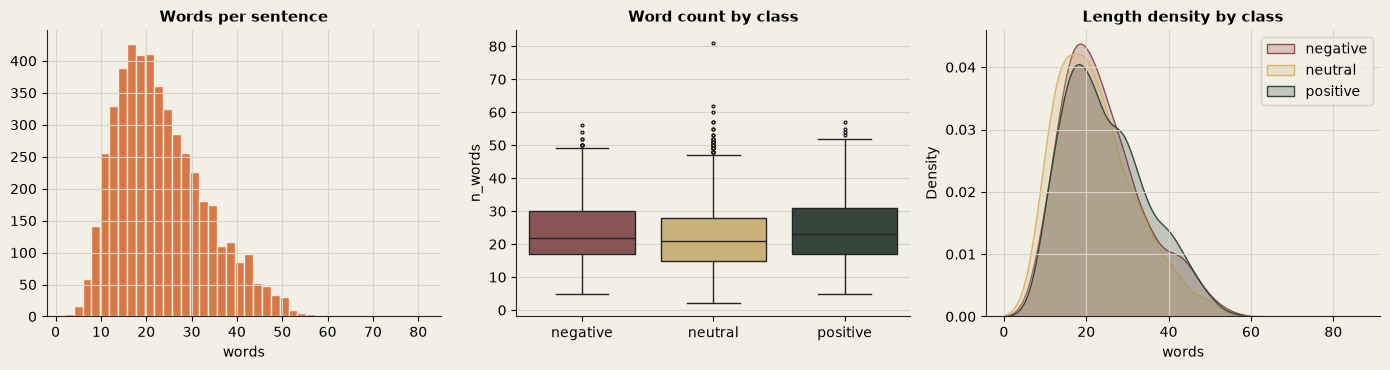

IQR rule: unusually long > 48 words -> 66 sentences; very short (<=5 words) -> 20 sentences
Class mix of long: {'neutral': 0.56, 'positive': 0.29, 'negative': 0.15} | short: {'neutral': 0.9, 'positive': 0.05, 'negative': 0.05}


,sentence,label_name,n_words
1116,Welcome !,neutral,2
2518,Net investment income,neutral,3
2569,Status : Agreed,neutral,3
3061,NWC ANALYSIS :,neutral,3
2399,All rights reserved .,neutral,4


,sentence,label_name,n_words
1863,"Supported Nokia phones include : N96 , N95-8GB , N95 , N93-N931 , N92 , N85 , N82 , N81 , N80 , N79 , N78 , N77 , N76 , N75 , N73 , N72 ...",neutral,81
2837,"Body ES Vostok also owns stakes in power sales companies MosenergosbytBody ( RTS : MSSB ) ( 50.9 % ) , Altaienergosbyt ( 100 % ) , Sarat...",neutral,62
2537,"Our customers come from the following countries : UK , USA , Spain , France , Italy , Germany , China , Sweden , Norway , Netherlands , ...",neutral,60


In [5]:
df["n_chars"] = df.sentence.str.len()
df["n_words"] = df.sentence.str.split().str.len()
desc = df[["n_chars","n_words"]].agg(["mean","median","min","max","std"]).round(2)
display(desc)
display(df.groupby("label_name")["n_words"].agg(["count","mean","median","std","min","max"]).reindex(CLS).round(2))
groups = [df.n_words[df.label_name == c] for c in CLS]
H, p = stats.kruskal(*groups)
eps2 = (H - 3 + 1) / (len(df) - 3)
print(f"Kruskal-Wallis on word count by class: H={H:.1f}, p={p:.2e}, epsilon^2 (effect size)={eps2:.4f}")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(df.n_words, bins=40, color=COPPER, edgecolor=PAPER); ax[0].set_title("Words per sentence"); ax[0].set_xlabel("words")
sns.boxplot(data=df, x="label_name", y="n_words", order=CLS, palette=CC, ax=ax[1], fliersize=2); ax[1].set_title("Word count by class"); ax[1].set_xlabel("")
for c in CLS: sns.kdeplot(df.n_words[df.label_name == c], ax=ax[2], color=CC[c], label=c, fill=True, alpha=.25, clip=(0, None))
ax[2].legend(); ax[2].set_title("Length density by class"); ax[2].set_xlabel("words")
fig.tight_layout(); save(fig, "C_length")
q1, q3 = df.n_words.quantile([.25, .75]); iqr = q3 - q1; hi = q3 + 1.5 * iqr
short, long_ = df[df.n_words <= 5], df[df.n_words > hi]
print(f"IQR rule: unusually long > {hi:.0f} words -> {len(long_)} sentences; very short (<=5 words) -> {len(short)} sentences")
print("Class mix of long:", long_.label_name.value_counts(normalize=True).round(2).to_dict(), "| short:", short.label_name.value_counts(normalize=True).round(2).to_dict())
display(short.sort_values("n_words").head(5)[["sentence","label_name","n_words"]]); display(long_.sort_values("n_words", ascending=False).head(3)[["sentence","label_name","n_words"]])

**Interpretation (C) — Text length**

- **Investigated:** characters and words per sentence, overall and by class.
- **Revealed:** mean **23.1 words** (median 21, sd 10.0, range 2–81); mean 128 characters. By class (mean words): negative 23.9, neutral 22.2, positive 24.7. The difference is statistically detectable (Kruskal–Wallis p ≈ 9e-15) but the **effect size is tiny (ε² = 0.013)**: length explains about 1% of rank variance. Very short sentences (≤5 words, n=20) are 90% neutral and are mostly headings/boilerplate (*"Welcome !"*, *"All rights reserved ."*). The 66 sentences above 48 words (IQR rule) are 56% neutral and include list-like text (phone model lists, country lists).
- **Why it matters:** length is *not* a useful sentiment signal — we should not treat long sentences as more positive or negative. The short/long outliers are real text, not corruption.
- **Implication:** no length-based filtering or length features. Length is relevant only through TF-IDF's L2 normalisation, which already removes most length effects. Boilerplate/list sentences are neutral by nature and harmless.

## Section D — Linguistic analysis
*Investigated:* vocabulary, frequent words/bigrams/trigrams, punctuation, capitalisation, numerics, lexical diversity.

Alphabetic tokens: 95,360 | vocabulary (lower-cased): 9,077 | case-sensitive whitespace types: 12,971
Hapax legomena (appear once): 4,478 = 49.3% of vocabulary
Type-token ratio: 0.0952 | Herdan's C (log V / log N): 0.795 | mean words/sentence: 19.68
Content tokens after stopword removal: 59023 | stopword share of all tokens: 38.1%
Top 10 raw words: [('the', 6069), ('of', 3216), ('in', 2984), ('and', 2596), ('to', 2523), ('a', 1761), ('eur', 1415), ('for', 1152), ('s', 1115), ('is', 930)]


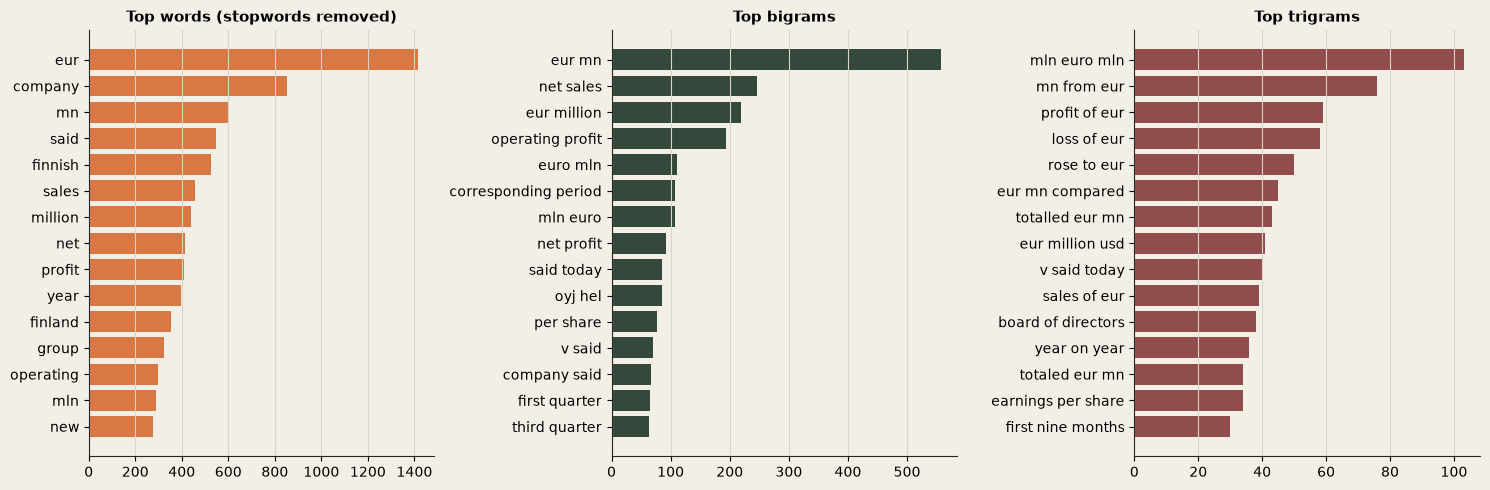

In [6]:
TOK = re.compile(r"[a-z]+(?:'[a-z]+)?")
def words(t): return TOK.findall(t.lower())
def content(toks): return [w for w in toks if w not in STOP and len(w) > 1]
def ngr(toks, n): return [" ".join(toks[i:i+n]) for i in range(len(toks) - n + 1)]
def content_ngr(toks, n):   # drop n-grams that start or end with a stopword ("of the", "in the")
    return [g for g in ngr(toks, n) if g.split()[0] not in STOP and g.split()[-1] not in STOP]
df["toks"] = df.sentence.map(words); df["ctoks"] = df.toks.map(content)
all_toks = [w for t in df.toks for w in t]
vocab = Counter(all_toks); hapax = sum(1 for v in vocab.values() if v == 1)
raw_vocab = len({w for s_ in df.sentence for w in s_.split()})
N, V = len(all_toks), len(vocab)
print(f"Alphabetic tokens: {N:,} | vocabulary (lower-cased): {V:,} | case-sensitive whitespace types: {raw_vocab:,}")
print(f"Hapax legomena (appear once): {hapax:,} = {100*hapax/V:.1f}% of vocabulary")
print(f"Type-token ratio: {V/N:.4f} | Herdan's C (log V / log N): {np.log(V)/np.log(N):.3f} | mean words/sentence: {df.toks.str.len().mean():.2f}")
print("Content tokens after stopword removal:", sum(map(len, df.ctoks)), "| stopword share of all tokens: %.1f%%" % (100 * (1 - sum(map(len, df.ctoks)) / N)))
top_all = Counter(all_toks).most_common(10); print("Top 10 raw words:", top_all)
cw = Counter(w for t in df.ctoks for w in t)
bg = Counter(g for t in df.toks for g in content_ngr(t, 2)); tg = Counter(g for t in df.toks for g in content_ngr(t, 3))
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (title, c, col) in zip(ax, [("Top words (stopwords removed)", cw, COPPER), ("Top bigrams", bg, FOREST), ("Top trigrams", tg, BURG)]):
    items = c.most_common(15)[::-1]; a.barh([k for k, _ in items], [v for _, v in items], color=col); a.set_title(title); a.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "D_top_ngrams")

,.,",",-,',`,),(,%,:,$
occurrences,7395.0,5114.0,1937.0,1587.0,554.0,527.0,525.0,445.0,390.0,236.0
sentences_containing_%,99.5,56.7,26.3,24.1,5.8,7.3,7.3,6.8,6.4,3.4


Start with capital: 92.9% | mean share of capitalised words (excl. first): 16.3% | mean ALL-CAPS tokens/sentence: 0.59


,has_num,has_pct,has_cur,has_year
label_name,,,,
negative,75.3,15.4,43.5,41.7
neutral,46.6,5.6,15.2,20.6
positive,57.7,14.2,31.4,30.8
ALL,53.3,9.2,23.3,26.1


chi-square has_pct vs label: p=2.31e-25
chi-square has_cur vs label: p=8.73e-65


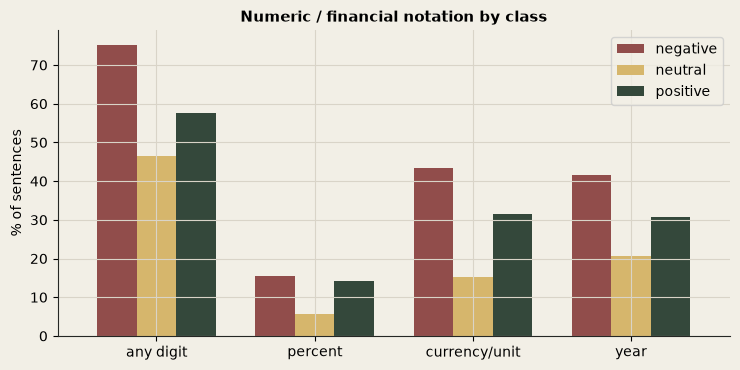

In [7]:
# punctuation, capitalisation, numerics
punct = Counter(ch for s_ in df.sentence for ch in s_ if not ch.isalnum() and not ch.isspace())
pshare = {ch: df.sentence.str.contains(re.escape(ch)).mean() for ch, _ in punct.most_common(10)}
display(pd.DataFrame({"occurrences": dict(punct.most_common(10)), "sentences_containing_%": {k: round(100*v, 1) for k, v in pshare.items()}}).T)
first_upper = df.sentence.str[0].str.isupper().mean()
cap_share = df.sentence.map(lambda s_: np.mean([w[0].isupper() for w in s_.split()[1:] if w[0].isalpha()] or [0]))
allcaps = df.sentence.map(lambda s_: sum(1 for w in s_.split() if len(w) > 1 and w.isupper() and w.isalpha()))
print(f"Start with capital: {100*first_upper:.1f}% | mean share of capitalised words (excl. first): {100*cap_share.mean():.1f}% | mean ALL-CAPS tokens/sentence: {allcaps.mean():.2f}")
CUR = r"(?:EUR|USD|GBP|SEK|\$|€|£|\bmn\b|\bbn\b|\bmillion\b|\bbillion\b)"
df["has_num"] = df.sentence.str.contains(r"\d"); df["has_pct"] = df.sentence.str.contains(r"%|\bper cent\b|\bpercent\b")
df["has_cur"] = df.sentence.str.contains(CUR); df["has_year"] = df.sentence.str.contains(r"\b(?:19|20)\d{2}\b")
num_tab = (df.groupby("label_name")[["has_num","has_pct","has_cur","has_year"]].mean().reindex(CLS) * 100).round(1)
num_tab.loc["ALL"] = (df[["has_num","has_pct","has_cur","has_year"]].mean() * 100).round(1); display(num_tab)
for col in ["has_pct", "has_cur"]:
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[col], df.label)); print(f"chi-square {col} vs label: p={p:.2e}")
fig, ax = plt.subplots(figsize=(7.5, 3.8)); num_tab.drop("ALL").T.plot.bar(ax=ax, color=[CC[c] for c in CLS], rot=0, width=.75)
ax.set_ylabel("% of sentences"); ax.set_title("Numeric / financial notation by class"); ax.set_xticklabels(["any digit", "percent", "currency/unit", "year"]); ax.legend(title="")
fig.tight_layout(); save(fig, "D_numeric_by_class")

**Interpretation (D) — Linguistic analysis**

- **Investigated:** vocabulary, n-grams, punctuation, capitalisation, numerics, diversity.
- **Revealed:** 95,360 alphabetic tokens, **9,077 distinct (lower-cased) words**; **49.3% of the vocabulary occurs only once** (hapax) — a long, sparse tail. Type–token ratio 0.095 (Herdan's C 0.795). Stopwords are 38.1% of tokens. After stopword removal, the dominant terms are **financial reporting boilerplate**: *eur, mn, company, profit, net, sales, operating, period*; top bigrams *eur mn, net sales, operating profit, eur million*; top trigrams are templates such as *"profit of eur"*, *"mn from eur"*. Punctuation: periods in 99.5% of sentences, commas in 56.7%, `%` in 6.8%. 92.9% start with a capital letter; ~16% of non-initial words are capitalised (company/place names); 0.59 ALL-CAPS tokens per sentence.
- **Numerics are strongly class-dependent:** sentences containing a digit — negative **75%**, positive 58%, neutral **47%**; a currency/unit marker — 43.5% / 31.4% / 15.2%; a percent sign — 15.4% / 14.2% / 5.6% (chi-square p < 1e-24 for both % and currency). Neutral text is mostly descriptive (business descriptions, announcements); polar text mostly reports figures.
- **Why it matters:** the most *frequent* words (*eur, mn, company, net, sales, profit*) occur in all classes, so **frequency ≠ discriminative power**; the sentiment lives in the words that change the meaning of those figures (*rose / fell / loss / decreased*) and in their order. Word clouds of the frequent words would mostly show the boilerplate, which is why they were not used.
- **Implication:** keep numbers in the text (number presence carries signal), lower-case, use unigrams **and bigrams** (*"operating profit"*, *"net loss"* are meaningful units), and expect a high-dimensional sparse space with half the vocabulary seen once → `min_df` pruning is justified.

## Section E — Class-wise linguistic analysis
*Investigated:* what each class talks about, and which terms are disproportionately associated with it (association ≠ causation).

In [8]:
def top_table(fn, k=10):
    out = {}
    for c in CLS:
        cnt_ = Counter(x for t in df.loc[df.label_name == c, "toks"] for x in fn(t)); out[c] = [f"{w} ({n})" for w, n in cnt_.most_common(k)]
    return pd.DataFrame(out)
print("TOP WORDS (stopwords removed)"); display(top_table(content))
print("TOP BIGRAMS"); display(top_table(lambda t: content_ngr(t, 2)))
print("TOP TRIGRAMS"); display(top_table(lambda t: content_ngr(t, 3)))
rng = np.random.default_rng(config.RANDOM_SEED)
class_toks = {c: [w for t in df.loc[df.label_name == c, "toks"] for w in t] for c in CLS}
m = min(len(v) for v in class_toks.values())
def eq_ttr(toks, n=m, reps=30): return np.mean([len(set(rng.choice(toks, n, replace=False))) / n for _ in range(reps)])
stats_c = pd.DataFrame({"sentences": df.label_name.value_counts().reindex(CLS), "mean_words": df.groupby("label_name").n_words.mean().reindex(CLS).round(2),
    "vocab_size": {c: len(set(v)) for c, v in class_toks.items()}, f"TTR@{m}_tokens": {c: round(eq_ttr(np.array(v)), 4) for c, v in class_toks.items()}})
display(stats_c)

TOP WORDS (stopwords removed)


,negative,neutral,positive
0,eur (417),company (510),eur (639)
1,mn (237),eur (359),mn (264)
2,profit (156),said (238),company (241)
3,net (104),finland (228),said (230)
4,finnish (102),finnish (220),year (212)
5,company (100),business (195),finnish (202)
6,year (100),million (193),net (196)
7,sales (98),group (190),sales (192)
8,operating (97),new (189),profit (192)
9,period (90),sales (165),million (170)


TOP BIGRAMS


,negative,neutral,positive
0,eur mn (231),net sales (96),eur mn (252)
1,operating profit (58),eur million (83),net sales (102)
2,net sales (48),eur mn (74),operating profit (101)
3,eur million (45),company said (40),eur million (91)
4,corresponding period (44),share capital (37),corresponding period (63)
5,net profit (34),mln euro (36),net profit (52)
6,euro mln (30),euro mln (35),euro mln (45)
7,mn compared (28),operating profit (35),mln euro (44)
8,mln euro (27),stock exchange (33),said today (44)
9,third quarter (26),omx helsinki (31),profit rose (43)


TOP TRIGRAMS


,negative,neutral,positive
0,profit of eur (34),mln euro mln (33),rose to eur (49)
1,mn from eur (28),board of directors (32),mn from eur (48)
2,eur mn compared (27),sales of eur (25),mln euro mln (43)
3,mln euro mln (27),eur per share (18),loss of eur (28)
4,totalled eur mn (26),nasdaq omx helsinki (14),year on year (27)
5,loss of eur (24),annual general meeting (14),v said today (23)
6,decreased to eur (24),n n n (14),first nine months (23)
7,compared to eur (19),stock exchange release (12),eur million usd (23)
8,fell to eur (15),profit of eur (12),operating profit rose (21)
9,totaled eur mn (14),headquartered in helsinki (11),month period increased (19)


,sentences,mean_words,vocab_size,TTR@11838_tokens
negative,604,23.92,2010,0.1698
neutral,2879,22.18,7237,0.2614
positive,1363,24.69,4201,0.2182


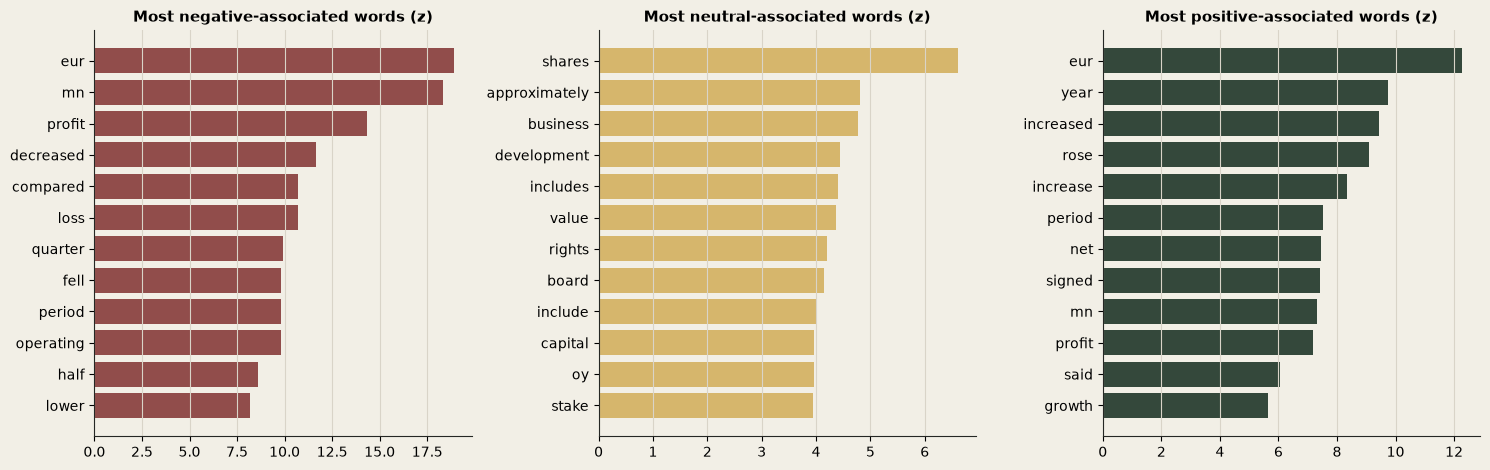

Most class-associated BIGRAMS (log-odds z, min count 8)


,negative,neutral,positive
0,"eur mn (z=18.5, n=231.0)","share capital (z=3.5, n=37.0)","eur mn (z=7.2, n=252.0)"
1,"corresponding period (z=7.8, n=44.0)","alma media (z=3.3, n=29.0)","operating profit (z=6.1, n=101.0)"
2,"mn compared (z=7.6, n=28.0)","voting rights (z=3.2, n=26.0)","corresponding period (z=5.8, n=63.0)"
3,"first half (z=7.6, n=26.0)","general meeting (z=2.8, n=21.0)","net profit (z=4.9, n=52.0)"
4,"operating loss (z=7.2, n=23.0)","real estate (z=2.7, n=27.0)","nine months (z=4.9, n=26.0)"
5,"totalled eur (z=7.1, n=26.0)","new shares (z=2.7, n=19.0)","first nine (z=4.6, n=23.0)"
6,"operating profit (z=6.8, n=58.0)","eur per (z=2.7, n=19.0)","net loss (z=4.5, n=30.0)"
7,"net profit (z=6.3, n=34.0)","helsinki finland (z=2.2, n=13.0)","v said (z=4.2, n=39.0)"


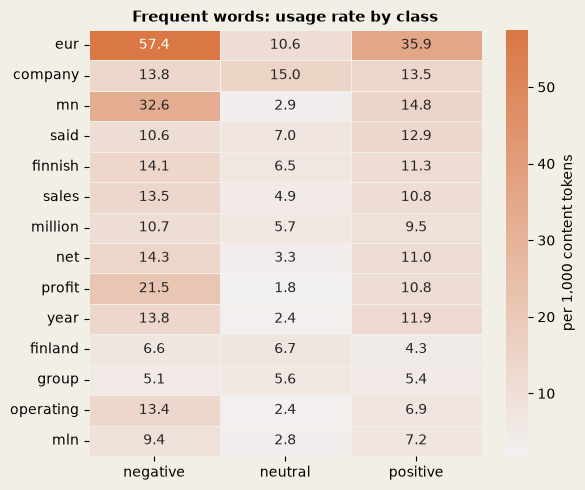

In [9]:
# Log-odds ratio with informative Dirichlet prior (Monroe et al. 2008): z-score of how much more a term is used in one class than in all others.
def log_odds(token_lists_by_class, target, min_count=8, alpha0=500):
    cm = pd.DataFrame({c: Counter(x for t in toks for x in t) for c, toks in token_lists_by_class.items()}).fillna(0)
    yi, yj = cm[target], cm.drop(columns=target).sum(axis=1); ni, nj = yi.sum(), yj.sum()
    a = (yi + yj) / (ni + nj) * alpha0
    delta = np.log((yi + a) / (ni + alpha0 - yi - a)) - np.log((yj + a) / (nj + alpha0 - yj - a))
    z = delta / np.sqrt(1 / (yi + a) + 1 / (yj + a))
    out = pd.DataFrame({"z": z, "in_class": yi.astype(int), "elsewhere": yj.astype(int)}); return out[(yi + yj) >= min_count].sort_values("z", ascending=False)
by_class = {c: df.loc[df.label_name == c, "ctoks"] for c in CLS}
LO = {c: log_odds(by_class, c) for c in CLS}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
for a_, c in zip(ax, CLS):
    t = LO[c].head(12)[::-1]; a_.barh(t.index, t.z, color=CC[c]); a_.set_title(f"Most {c}-associated words (z)"); a_.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "E_log_odds_words")
bg_by_class = {c: df.loc[df.label_name == c, "toks"].map(lambda t: content_ngr(t, 2)) for c in CLS}
print("Most class-associated BIGRAMS (log-odds z, min count 8)")
display(pd.DataFrame({c: [f"{g} (z={r.z:.1f}, n={r.in_class})" for g, r in log_odds(bg_by_class, c, min_count=8).head(8).iterrows()] for c in CLS}))
# normalised frequency per 1,000 content tokens for the 14 most frequent content words
top14 = [w for w, _ in cw.most_common(14)]
nf = pd.DataFrame({c: [1000 * sum(t.count(w) for t in by_class[c]) / sum(map(len, by_class[c])) for w in top14] for c in CLS}, index=top14)
fig, ax = plt.subplots(figsize=(6, 5)); sns.heatmap(nf, annot=True, fmt=".1f", cmap=sns.light_palette(COPPER, as_cmap=True), cbar_kws={"label": "per 1,000 content tokens"}, ax=ax, linewidths=.5, linecolor=PAPER)
ax.set_title("Frequent words: usage rate by class"); ax.grid(False); fig.tight_layout(); save(fig, "E_frequent_words_by_class")

**Interpretation (E) — Class-wise analysis**

- **Investigated:** per-class frequent words/bigrams/trigrams, diversity, and log-odds (informative Dirichlet prior) association scores.
- **Revealed:** the raw per-class top lists look alike: *eur, mn, profit, sales, net, company* head both polar classes. What differs is **breadth**: at an equal sample of 11,838 tokens per class, the type–token ratio is neutral **0.261**, positive 0.218, negative **0.170** — neutral text is lexically varied (many different topics: companies, locations, announcements), whereas negative text is narrow and templated (*"profit of EUR … mn"*, *"decreased to EUR"*, *"fell to EUR"*, *"operating loss"*). Neutral-associated bigrams are corporate-event vocabulary (*share capital, voting rights, general meeting, real estate*). Polar-associated bigrams are reporting phrases (*corresponding period, operating profit, net profit, first half, nine months*). The log-odds figure (`E_log_odds_words.png`) shows that *eur* and *mn* rank at the very top for **both** polar classes — simply because neutral text uses them far less (a "this sentence reports figures" signal, not a sentiment one). The genuinely sentiment-bearing words sit just below: negative → *decreased, loss, fell, lower, operating*; positive → *increased, rose, increase, growth, signed*; neutral → *shares, approximately, business, development, rights, board, stake*.
- **Caveat that matters:** the trigram *"loss of eur"* is a top-10 **positive** trigram (28 occurrences) as well as a top negative one (24) — typically *"…moved from a loss of EUR x to a profit"*. The same words appear on both sides; the **direction** is carried by surrounding words and order.
- **Association, not causation:** these are co-occurrence statistics in a sample of Finnish/Nordic-heavy news (*finnish*, *finland* are top words). A term being class-associated does not mean it *causes* a sentiment, and some associations reflect corpus topics or reporting style, not sentiment itself.
- **Implication:** linear models on TF-IDF unigrams+bigrams should work reasonably, but errors are expected on sentences where polarity words co-occur (profit/loss, up/down). Use per-class metrics, and treat influential-word explanations in the app as *statistical associations*.

## Section F — Financial vocabulary
*Investigated:* a small, **manually defined** lexicon (not a complete financial dictionary). Matching is on exact lower-cased word forms listed below; some words are ambiguous (e.g. *share*, *interest*), which is a limitation.

Terms in >1 category: []
Baseline class mix (%): {'negative': 12.5, 'neutral': 59.4, 'positive': 28.1}


,sentences,coverage_%,%negative,%neutral,%positive,chi2_p,cramers_V
category,,,,,,,
Revenue & profitability,945,19.5,29.7,25.3,45.0,2.1e-137,0.360
Losses & expenses,240,5.0,38.3,18.3,43.3,3.0e-50,0.217
Growth & expansion,555,11.5,6.1,18.4,75.5,2.9e-152,0.379
Debt & liabilities,104,2.1,4.8,73.1,22.1,7.8e-03,0.045
Investments & acquisitions,364,7.5,3.8,70.6,25.5,8.0e-08,0.082
Market performance,565,11.7,12.7,63.7,23.5,3.3e-02,0.038
Risk & uncertainty,273,5.6,76.2,17.6,6.2,1.3e-234,0.471
Dividends & shareholder returns,125,2.6,1.6,80.8,17.6,1.3e-06,0.075


Most frequent lexicon terms: [('sales', 428, 'Revenue & pr'), ('profit', 406, 'Revenue & pr'), ('market', 203, 'Market perfo'), ('shares', 161, 'Market perfo'), ('loss', 142, 'Losses & exp'), ('rose', 101, 'Growth & exp'), ('increase', 100, 'Growth & exp'), ('increased', 99, 'Growth & exp'), ('investment', 97, 'Investments '), ('stock', 88, 'Market perfo'), ('decreased', 77, 'Risk & uncer'), ('price', 73, 'Market perfo'), ('growth', 65, 'Growth & exp'), ('acquisition', 65, 'Investments '), ('fell', 54, 'Risk & uncer')]
Lexicon coverage: 47.1% of sentences contain >=1 lexicon term


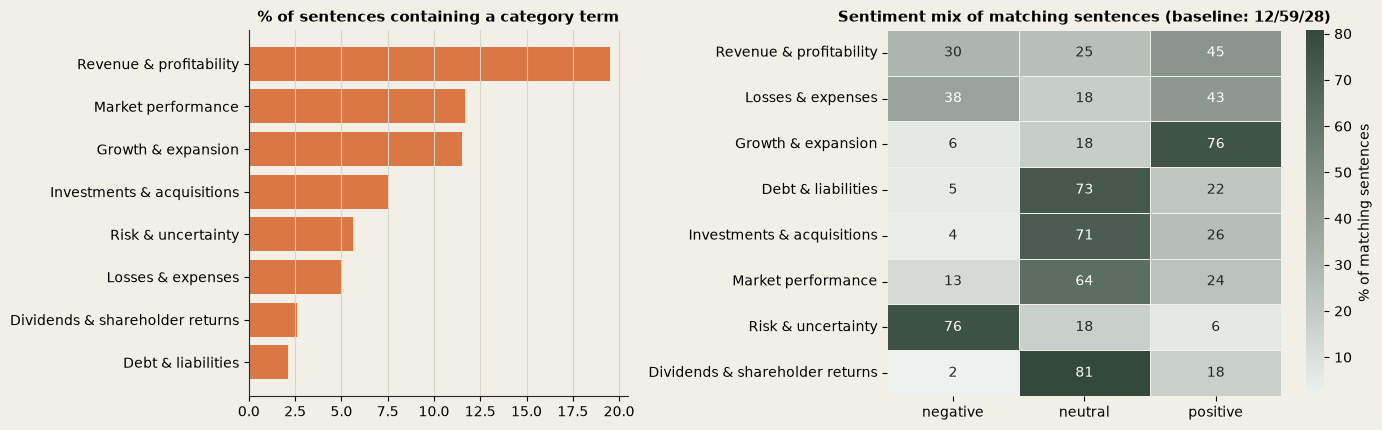

Individual terms (n>=30): sentiment mix


term,sales,profit,market,shares,loss,rose,increase,increased,investment,stock,...,cost,lower,turnover,acquired,shareholders,distribution,grew,prices,costs,dividend
n,428,406,203,161,142,101,100,99,97,88,...,39,39,38,37,37,35,34,32,32,31
%neg,21,38,11,11,46,4,0,13,5,9,...,8,72,24,0,3,0,0,34,34,0
%neu,36,15,59,80,8,4,27,7,74,67,...,31,18,47,89,84,74,3,38,28,81
%pos,42,47,31,9,46,92,73,80,21,24,...,62,10,29,11,14,26,97,28,38,19


In [10]:
LEXICON = {
 "Revenue & profitability": "revenue revenues sales profit profits profitability profitable earnings income margin margins ebitda ebit turnover".split(),
 "Losses & expenses": "loss losses costs cost expenses expense deficit writedown impairment charges layoffs layoff redundancies".split(),
 "Growth & expansion": "growth grow grew growing increase increased increases rose rise rising expansion expand expanded expanding boost improved improvement higher".split(),
 "Debt & liabilities": "debt debts loan loans borrowing liabilities liability credit bond bonds leverage convertible interest".split(),
 "Investments & acquisitions": "investment investments invest invested acquisition acquisitions acquire acquired acquires merger stake buyout divest divestment takeover".split(),
 "Market performance": "shares stock stocks market price prices index trading volume".split(),
 "Risk & uncertainty": "risk risks uncertainty uncertain volatility volatile weak weaker weakness warning warned concern concerns pressure downturn recession crisis decline declined decrease decreased fall fell drop dropped lower".split(),
 "Dividends & shareholder returns": "dividend dividends payout buyback repurchase shareholders shareholder yield distribution".split(),
}
assert all(len(set(v)) == len(v) for v in LEXICON.values())
term2cat = {w: c for c, ws in LEXICON.items() for w in ws}
dup_terms = [w for w in term2cat if sum(w in ws for ws in LEXICON.values()) > 1]; print("Terms in >1 category:", dup_terms)
tokset = df.toks.map(set)
rows = []
for cat, ws in LEXICON.items():
    has = tokset.map(lambda s_: bool(s_ & set(ws)))
    ct = df[has].label_name.value_counts(normalize=True).reindex(CLS).fillna(0) * 100
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(has, df.label)); V_ = np.sqrt(chi2 / len(df))
    rows.append({"category": cat, "sentences": int(has.sum()), "coverage_%": round(100 * has.mean(), 1), **{f"%{c}": round(ct[c], 1) for c in CLS}, "chi2_p": f"{p:.1e}", "cramers_V": round(V_, 3)})
cat_tab = pd.DataFrame(rows).set_index("category"); base = (100 * df.label_name.value_counts(normalize=True)).reindex(CLS).round(1)
print("Baseline class mix (%):", base.to_dict()); display(cat_tab)
term_counts = Counter(w for t in df.toks for w in sorted(set(t)) if w in term2cat)   # sorted: deterministic tie order
print("Most frequent lexicon terms:", [(w, n, term2cat[w][:12]) for w, n in term_counts.most_common(15)])
print("Lexicon coverage: %.1f%% of sentences contain >=1 lexicon term" % (100 * tokset.map(lambda s_: bool(s_ & set(term2cat))).mean()))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
ct_ = cat_tab.sort_values("coverage_%"); ax[0].barh(ct_.index, ct_["coverage_%"], color=COPPER); ax[0].set_title("% of sentences containing a category term"); ax[0].grid(axis="y", visible=False)
lift = cat_tab[[f"%{c}" for c in CLS]].copy(); lift.columns = CLS
sns.heatmap(lift, annot=True, fmt=".0f", cmap=sns.light_palette(FOREST, as_cmap=True), ax=ax[1], cbar_kws={"label": "% of matching sentences"}, linewidths=.5, linecolor=PAPER)
ax[1].set_title(f"Sentiment mix of matching sentences (baseline: {base['negative']:.0f}/{base['neutral']:.0f}/{base['positive']:.0f})"); ax[1].set_ylabel(""); ax[1].grid(False)
fig.tight_layout(); save(fig, "F_financial_vocabulary")
term_rows = []
for w, n in term_counts.most_common(40):
    if n >= 30:
        mix = df[tokset.map(lambda s_: w in s_)].label_name.value_counts(normalize=True).reindex(CLS).fillna(0) * 100
        term_rows.append({"term": w, "n": n, "%neg": round(mix["negative"]), "%neu": round(mix["neutral"]), "%pos": round(mix["positive"])})
print("Individual terms (n>=30): sentiment mix"); display(pd.DataFrame(term_rows).set_index("term").T)

**Interpretation (F) — Financial vocabulary**

*Lexicon: 8 hand-written categories (see code cell; not a complete financial dictionary; exact word-form matching; ambiguous words such as *share, interest, price* are a known limitation).* **47.1%** of sentences contain at least one lexicon term.

| Category (coverage) | neg / neu / pos % of matching sentences | Reading |
|---|---|---|
| Risk & uncertainty (5.6%) | **76** / 18 / 6 | strongest negative signal (Cramér's V 0.47) |
| Growth & expansion (11.5%) | 6 / 18 / **76** | strongest positive signal (V 0.38) |
| Revenue & profitability (19.5%) | 30 / 25 / **45** | **mixed** — profit can rise or fall |
| Losses & expenses (5.0%) | 38 / 18 / **43** | **mixed — more positive than negative!** |
| Debt & liabilities (2.1%) | 5 / **73** / 22 | mostly neutral |
| Investments & acquisitions (7.5%) | 4 / **71** / 26 | mostly neutral |
| Market performance (11.7%) | 13 / **64** / 24 | mostly neutral (near-baseline) |
| Dividends & shareholder returns (2.6%) | 2 / **81** / 18 | mostly neutral |

- **Why it matters:** topic words alone do not give sentiment. *Losses & expenses* sentences are **43% positive** because of phrasing like *"net loss narrowed"*, *"loss turned to profit"*. Individual terms confirm this: *loss* is 46% negative / 46% positive; *profit* 38% negative / 47% positive; but *rose*, *increase(d)*, *grew* are 73–97% positive and *lower* is 72% negative. **Direction words carry sentiment; money words only set the topic.** Neutral sentences are heavy on corporate-action vocabulary (acquired 89% neutral, shareholders 84%, dividend 81%).
- **Implication:** a pure lexicon/keyword approach would misclassify many sentences; models need word order/bigrams (*"loss narrowed"*), which supports including bigrams. Not all categories separate classes equally (Debt, Market performance have V < 0.05), so they are weak discriminators on their own.

## Section G — Data quality & outliers
*Investigated:* duplicates, near-duplicates, boilerplate, odd symbols, numeric-heavy text, and label-suspicious records. Examples shown; **no record is deleted without a documented reason.**

In [11]:
NUM = re.compile(r"\d+(?:[.,]\d+)*")
norm = df.sentence.str.lower().map(lambda s_: NUM.sub("<NUM>", s_))
grp = df.groupby(norm)
nd = grp.filter(lambda g: g.sentence.nunique() > 1)       # same template, different numbers/values
nd_groups = nd.groupby(norm[nd.index]).agg(n=("sentence", "size"), labels=("label", "nunique"))
print(f"Near-duplicate templates (identical after replacing numbers): {len(nd_groups)} groups covering {len(nd)} rows; groups with mixed labels: {(nd_groups.labels > 1).sum()}")
ex = nd.groupby(norm[nd.index]).head(2).sort_values("sentence").head(4); display(ex[["sentence", "label_name"]])
# numeric-heavy
digit_share = df.sentence.map(lambda s_: sum(ch.isdigit() for ch in s_) / len(s_)); df["digit_share"] = digit_share
print(f"Numeric-heavy (>=15% of characters are digits): {(digit_share >= .15).sum()} sentences; classes: {df[digit_share >= .15].label_name.value_counts().to_dict()}")
display(df[digit_share >= .15].sort_values("digit_share", ascending=False).head(3)[["sentence", "label_name"]])
# unusual symbols
odd = df.sentence.str.contains(r"[^A-Za-z0-9\s\.,;:%\(\)\-'\"/&\+\$€£#@!?\*]"); print("Rows with symbols outside the common set:", int(odd.sum()))
print("Source-encoding damage rows:", int(mojibake.sum()), "->", df[mojibake].label_name.value_counts().to_dict())
# boilerplate: repeated 5-grams across distinct sentences
rep = Counter(g for t in df.toks for g in sorted(set(ngr(t, 5))))   # sorted: deterministic tie order; print("Most repeated 5-word phrases (sentences containing):", [(g, n) for g, n in rep.most_common(6)])
# header-style noise: newswire prefixes
hdr = df.sentence.str.match(r"^[A-Z0-9\-]{6,}[ \-]"); print("Sentences starting with newswire/ticker-style header:", int(hdr.sum())); display(df[hdr].sentence.head(3).to_frame())

Near-duplicate templates (identical after replacing numbers): 22 groups covering 52 rows; groups with mixed labels: 2


,sentence,label_name
2342,"Ahlstrom 's 5,700 employees serve customers via sales offices and production facilities in more than 20 countries on six continents .",neutral
2394,"Ahlstrom 's 5,800 employees serve customers via sales offices and production facilities in more than 20 countries on six continents .",neutral
161,"Both operating profit and net sales for the 12-month period increased , respectively from EUR10 .5 m and EUR28 .8 m , as compared to the...",positive
162,"Both operating profit and net sales for the 12-month period increased , respectively from EUR20 .8 m and EUR177 .7 m , as compared to th...",positive


Numeric-heavy (>=15% of characters are digits): 85 sentences; classes: {'neutral': 40, 'positive': 27, 'negative': 18}


,sentence,label_name
1863,"Supported Nokia phones include : N96 , N95-8GB , N95 , N93-N931 , N92 , N85 , N82 , N81 , N80 , N79 , N78 , N77 , N76 , N75 , N73 , N72 ...",neutral
2352,"H1 '08 H1 '07 Q2 '08 Q2 '07 in mln euro , unless otherwise stated Net sales 386 328.6 201 160.7 Operating profit 46.3 35.8 23.2 9.5 Pre-...",neutral
3720,"pct lower at 4,442.10 .",neutral


Rows with symbols outside the common set: 394
Source-encoding damage rows: 91 -> {'neutral': 53, 'positive': 25, 'negative': 13}
Sentences starting with newswire/ticker-style header: 80


,sentence
5,FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is aggressively pursuing its growth strategy by increasingly focusing on technologically more d...
17,"HELSINKI ( AFX ) - Shares closed higher , led by Nokia after it announced plans to team up with Sanyo to manufacture 3G handsets , and b..."
78,TELECOMWORLDWIRE-7 April 2006-TJ Group Plc sells stake in Morning Digital Design Oy Finnish IT company TJ Group Plc said on Friday 7 Apr...


In [12]:
# label-suspicious records: polar sentences whose strongest cue words point the other way (candidates for review, NOT proven errors)
NEGW = set(LO["negative"].head(25).index); POSW = set(LO["positive"].head(25).index)
def n_hits(toks, S): return len(set(toks) & S)
df["neg_hits"] = df.ctoks.map(lambda t: n_hits(t, NEGW)); df["pos_hits"] = df.ctoks.map(lambda t: n_hits(t, POSW))
sus_pos = df[(df.label_name == "positive") & (df.neg_hits >= 1) & (df.pos_hits == 0)]
sus_neg = df[(df.label_name == "negative") & (df.pos_hits >= 1) & (df.neg_hits == 0)]
sus_neu = df[(df.label_name == "neutral") & ((df.pos_hits >= 2) | (df.neg_hits >= 2))]
print(f"'positive' with only negative-cue words: {len(sus_pos)} | 'negative' with only positive-cue words: {len(sus_neg)} | 'neutral' with >=2 polar cues: {len(sus_neu)}")
for name, d_ in [("positive-labelled, negative cues", sus_pos), ("negative-labelled, positive cues", sus_neg), ("neutral-labelled, strong cues", sus_neu)]:
    print("\n" + name); display(d_.head(3)[["sentence", "label_name"]])
# leakage risk: near-duplicate templates spread across train / validation / test
cdf, tr, va, te = D.get_splits()
cn = cdf.sentence.str.lower().map(lambda s_: NUM.sub("<NUM>", s_))
tr_templates = set(cn[tr]); print(f"\nValidation sentences whose number-normalised template also occurs in TRAIN: {cn[va].isin(tr_templates).mean()*100:.1f}%  | test: {cn[te].isin(tr_templates).mean()*100:.1f}%")
print("Cleaned set:", len(cdf), "rows (from", len(df), ") | train/val/test =", len(tr), len(va), len(te))
decisions = pd.DataFrame([
  ("Conflicting-label sentences", "DROP all copies", "Annotation is ambiguous; any chosen label would be a guess"),
  ("Exact duplicates, same label", "KEEP one copy", "Prevents the same sentence landing in train and test (leakage)"),
  ("Source-encoding damage ('+ñ')", "KEEP unchanged", "Affects names mostly; repairs would be guesswork; rare tokens are pruned by min_df"),
  ("Very short / very long sentences", "KEEP", "Legitimate text; no evidence of error"),
  ("Numeric-heavy sentences", "KEEP", "Numbers are informative (growth / decline figures)"),
  ("Near-duplicate templates", "KEEP, flag risk", "Different values can change sentiment; cannot dedupe safely; may mildly inflate scores"),
  ("Suspicious-label candidates", "KEEP", "Cue-word heuristics are not proof of annotation error"),
  ("Stopword removal", "NOT applied blindly", "NLTK list contains negations (see Section I)"),
], columns=["issue", "decision", "reason"]); display(decisions.set_index("issue"))

'positive' with only negative-cue words: 21 | 'negative' with only positive-cue words: 37 | 'neutral' with >=2 polar cues: 340

positive-labelled, negative cues


,sentence,label_name
11,"STORA ENSO , NORSKE SKOG , M-REAL , UPM-KYMMENE Credit Suisse First Boston ( CFSB ) raised the fair value for shares in four of the larg...",positive
149,South African Sappi will become the largest foreign forest industry company operating in Finland as a result of the acquisition Finnish ...,positive
552,More staff has been recruited in Japan to further complement its network of close to 50 service locations in more than 20 countries worl...,positive



negative-labelled, positive cues


,sentence,label_name
539,"Jan. 6 -- Ford is struggling in the face of slowing truck and SUV sales and a surfeit of up-to-date , gotta-have cars .",negative
544,"However , the growth margin slowed down due to the financial crisis .",negative
733,"At this growth rate , paying off the national debt will be extremely painful .",negative



neutral-labelled, strong cues


,sentence,label_name
59,"In Sweden , Gallerix accumulated SEK denominated sales were down 1 % and EUR denominated sales were up 11 % .",neutral
62,"`` The new agreement is a continuation to theagreement signed earlier this year with the Lemminkainen Group , whereby Cramo acquired the...",neutral
71,"- So , the sales growth of cars considerably influence on the tires market '' .",neutral



Validation sentences whose number-normalised template also occurs in TRAIN: 1.4%  | test: 0.8%
Cleaned set: 4836 rows (from 4846 ) | train/val/test = 3384 726 726


,decision,reason
issue,,
Conflicting-label sentences,DROP all copies,Annotation is ambiguous; any chosen label would be a guess
"Exact duplicates, same label",KEEP one copy,Prevents the same sentence landing in train and test (leakage)
Source-encoding damage ('+ñ'),KEEP unchanged,Affects names mostly; repairs would be guesswork; rare tokens are pruned by min_df
Very short / very long sentences,KEEP,Legitimate text; no evidence of error
Numeric-heavy sentences,KEEP,Numbers are informative (growth / decline figures)
Near-duplicate templates,"KEEP, flag risk",Different values can change sentiment; cannot dedupe safely; may mildly inflate scores
Suspicious-label candidates,KEEP,Cue-word heuristics are not proof of annotation error
Stopword removal,NOT applied blindly,NLTK list contains negations (see Section I)


**Interpretation (G) — Data quality & outliers**

- **Investigated:** duplicates, near-duplicates, short/long/numeric-heavy text, odd symbols, boilerplate, header noise, label-suspicious candidates.
- **Revealed:**
  - **Near-duplicate templates:** 22 groups (52 rows) are identical after replacing numbers (e.g. *"Ahlstrom's 5,700 vs 5,800 employees…"*); 2 groups have mixed labels. Leakage risk across our splits is small: **1.4%** of validation and **0.8%** of test sentences share a template with a training sentence.
  - **Numeric-heavy** (≥15% digit characters): 85 sentences (tables, model-number lists). **Newswire/ticker-style headers** (*"TELECOMWORLDWIRE-7 April 2006-…"*, *"HELSINKI ( AFX ) -"*): 80 sentences. **91** encoding-damaged rows. 394 rows contain symbols outside a common set (mostly quotes/backticks and the damage above).
  - **Boilerplate:** the most repeated 5-word phrases are reporting templates (*"to EUR mn from EUR"* in 70 sentences, *"in the corresponding period in"* in 63).
  - **Suspicious-label candidates** (cue-word heuristic): 21 *positive* sentences with only negative-cue words and 37 *negative* with only positive-cue words — e.g. *"However, the growth margin slowed down due to the financial crisis"* is correctly negative despite the positive word *growth*. These are mostly **context effects, not annotation errors**. The 340 neutral sentences with ≥2 polar cues are largely driven by ambiguous cue words (*sales*, *profit*), so this heuristic is weak evidence only.
- **Why it matters:** these quirks can inflate or distort scores, but none justify deleting data on their own.
- **Implication / cleaning decisions** (also in the table above): drop 4 rows (2 conflicting sentences × 2 copies), drop 6 same-label duplicate copies → **4,836 rows**; keep everything else; don't repair encoding; don't blindly remove stopwords.

## Section H — Agreement & annotation considerations
*Investigated:* the four agreement subsets released by the authors, how they nest, and whether 'contested' sentences are harder. **Only the aggregated label is available — no annotator-level labels — so Cohen's κ / individual reliability cannot be computed and is not claimed.**

In [13]:
from huggingface_hub import hf_hub_download
arch = hf_hub_download(config.DATASET_REPO, config.DATASET_ARCHIVE, repo_type="dataset")
def read_cfg(name):
    with zipfile.ZipFile(arch) as zf: txt = zf.read(f"FinancialPhraseBank-v1.0/Sentences_{name}.txt").decode("latin-1")
    rows = [l.rstrip("\r\n").rpartition("@") for l in txt.splitlines() if l.strip()]
    return pd.DataFrame({"sentence": [r[0].strip() for r in rows], "label_name": [r[2] for r in rows]})
cfgs = {n: read_cfg(n) for n in ["50Agree", "66Agree", "75Agree", "AllAgree"]}
summary = pd.DataFrame({k: {"rows": len(v), **{c: int((v.label_name == c).sum()) for c in CLS}, "neutral_%": round(100 * (v.label_name == "neutral").mean(), 1)} for k, v in cfgs.items()}).T; display(summary)
sets = {k: set(v.sentence) for k, v in cfgs.items()}
for small, big in [("AllAgree", "75Agree"), ("75Agree", "66Agree"), ("66Agree", "50Agree")]:
    print(f"{small} sentences also in {big}: {len(sets[small] & sets[big])}/{len(sets[small])} ({100*len(sets[small] & sets[big])/len(sets[small]):.1f}%)")
unan = set(cfgs["AllAgree"].sentence)
df["unanimous"] = df.sentence.isin(unan)
print("\nIn our 50% data: unanimous rows =", int(df.unanimous.sum()), "| contested (agreement < 100%) =", int((~df.unanimous).sum()))
print("Class mix (%): unanimous", (100*df[df.unanimous].label_name.value_counts(normalize=True).reindex(CLS)).round(1).to_dict(),
      "| contested", (100*df[~df.unanimous].label_name.value_counts(normalize=True).reindex(CLS)).round(1).to_dict())

,rows,negative,neutral,positive,neutral_%
50Agree,4846.0,604.0,2879.0,1363.0,59.4
66Agree,4217.0,514.0,2535.0,1168.0,60.1
75Agree,3453.0,420.0,2146.0,887.0,62.1
AllAgree,2264.0,303.0,1391.0,570.0,61.4


AllAgree sentences also in 75Agree: 2259/2259 (100.0%)
75Agree sentences also in 66Agree: 3448/3448 (100.0%)
66Agree sentences also in 50Agree: 4211/4211 (100.0%)

In our 50% data: unanimous rows = 2264 | contested (agreement < 100%) = 2582
Class mix (%): unanimous {'negative': 13.4, 'neutral': 61.4, 'positive': 25.2} | contested {'negative': 11.7, 'neutral': 57.6, 'positive': 30.7}


In [14]:
# Is contested text harder? Quick TF-IDF+LogReg fitted on TRAIN only, scored on VALIDATION only (test set untouched).
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
cdf["unanimous"] = cdf.sentence.isin(unan)
pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)), ("lr", LogisticRegression(max_iter=1000, C=10))])
pipe.fit(cdf.sentence[tr], cdf.label[tr]); pv = pipe.predict(cdf.sentence[va]); yv = cdf.label[va]; uv = cdf.unanimous[va].values
res = pd.DataFrame({k: {"n": int(m_.sum()), "accuracy": round(accuracy_score(yv[m_], pv[m_]), 3), "macro_F1": round(f1_score(yv[m_], pv[m_], average="macro"), 3)}
                    for k, m_ in {"unanimous": uv, "contested": ~uv, "all validation": np.ones(len(uv), bool)}.items()}).T; display(res)
from sklearn.metrics import confusion_matrix
print("Where do validation errors go? (rows=true, cols=pred; order neg/neu/pos)"); display(pd.DataFrame(confusion_matrix(yv, pv), index=CLS, columns=CLS))

,n,accuracy,macro_F1
unanimous,338.0,0.914,0.879
contested,388.0,0.683,0.585
all validation,726.0,0.791,0.730


Where do validation errors go? (rows=true, cols=pred; order neg/neu/pos)


,negative,neutral,positive
negative,49,33,9
neutral,7,396,28
positive,6,69,129


**Interpretation (H) — Agreement & annotation**

- **What agreement means:** each sentence was labelled by several annotators; `50Agree` keeps sentences where **at least 50%** agreed on the label, `AllAgree` only those with unanimity. Only the **aggregated label** is published — there are **no annotator-level labels**, so **individual reliability and Cohen's κ cannot be computed, and none is claimed.**
- **Overlap (computed):** the subsets are nested: AllAgree (2,264) ⊂ 75Agree (3,453) ⊂ 66Agree (4,217) ⊂ 50Agree (4,846); every sentence of each smaller set is in the larger (2259/2259, 3448/3448, 4211/4211 distinct sentences). So **50Agree = 2,264 unanimous + 2,582 contested** sentences. We use 50Agree only (not mixed with others) as specified.
- **Is contested text harder? Yes, clearly.** A quick TF-IDF+Logistic-Regression (fit on train, scored on **validation only**; test untouched) gets **accuracy 0.914 / macro-F1 0.879 on unanimous** validation sentences (n=338) versus **0.683 / 0.585 on contested** ones (n=388). Overall validation: 0.791 / 0.730. The largest confusion is **positive → neutral (69 of 204 positives)**; negative → neutral is also frequent (33 of 91).
- **Why it matters:** financial sentiment is subjective and context-dependent — whether *"operating profit rose to EUR 10m"* is "positive" depends on expectations, and whether a factual statement is *neutral* or mildly positive/negative is a judgement call. Neutral vs. polar is the hardest boundary.
- **Implication:** the 50Agree labels contain irreducible noise. **Expect a ceiling well below 100%** and don't over-interpret small macro-F1 differences between models (a difference of a point or two of macro-F1 on 726 validation samples is likely within noise). Report per-class results and confusion matrices.

## Section I — Feature representation
*Investigated:* tokenisation, stopwords, n-grams, TF-IDF, sparsity. **All vectorisers below are fitted on the TRAINING split only.**

In [15]:
ex = cdf.sentence[tr].iloc[3]; print("Sentence:", ex)
tk = words(ex); print("\n1 Tokens:", tk); print("2 Stopword-removed:", content(tk)); print("3 Unigrams:", len(tk), "| 4 Bigrams:", ngr(tk, 2)[:6], "...")
neg_in_stop = sorted(w for w in STOP if w in {"no","not","nor","against","don","didn","isn","won","wasn","aren","couldn","shouldn","wouldn","hasn","haven","hadn","doesn","weren","mightn","needn","shan","mustn","ain","ma","off","down","up","over","below","under","out"})
print("\nNLTK stopwords that carry direction/negation:", neg_in_stop)
from sklearn.feature_extraction.text import TfidfVectorizer
CONFIGS = {"A: unigram": dict(ngram_range=(1, 1), min_df=2, sublinear_tf=True),
           "B: uni+bigram": dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
           "C: uni+bigram, NLTK stopwords removed": dict(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words=sorted(STOP))}
Xtr_text, Xva_text = cdf.sentence[tr], cdf.sentence[va]; rows = []; fitted = {}
for name, kw in CONFIGS.items():
    v = TfidfVectorizer(lowercase=True, **kw).fit(Xtr_text); Xt, Xv = v.transform(Xtr_text), v.transform(Xva_text); fitted[name] = (v, Xt)
    analyzer = v.build_analyzer(); val_terms = [g for s_ in Xva_text for g in analyzer(s_)]; known = set(v.vocabulary_)
    rows.append({"config": name, "vocab_size": len(v.vocabulary_), "train_matrix": f"{Xt.shape[0]}x{Xt.shape[1]}", "non_zeros": Xt.nnz,
                 "sparsity_%": round(100 * (1 - Xt.nnz / (Xt.shape[0] * Xt.shape[1])), 3), "avg_active_features/doc": round(Xt.nnz / Xt.shape[0], 1),
                 "val_features_seen_in_train_%": round(100 * np.mean([g in known for g in val_terms]), 1)})
display(pd.DataFrame(rows).set_index("config"))

Sentence: For the last quarter of 2010 , Componenta 's net sales doubled to EUR131m from EUR76m for the same period a year earlier , while it moved to a zero pre-tax profit from a pre-tax loss of EUR7m .

1 Tokens: ['for', 'the', 'last', 'quarter', 'of', 'componenta', 's', 'net', 'sales', 'doubled', 'to', 'eur', 'm', 'from', 'eur', 'm', 'for', 'the', 'same', 'period', 'a', 'year', 'earlier', 'while', 'it', 'moved', 'to', 'a', 'zero', 'pre', 'tax', 'profit', 'from', 'a', 'pre', 'tax', 'loss', 'of', 'eur', 'm']
2 Stopword-removed: ['last', 'quarter', 'componenta', 'net', 'sales', 'doubled', 'eur', 'eur', 'period', 'year', 'earlier', 'moved', 'zero', 'pre', 'tax', 'profit', 'pre', 'tax', 'loss', 'eur']
3 Unigrams: 40 | 4 Bigrams: ['for the', 'the last', 'last quarter', 'quarter of', 'of componenta', 'componenta s'] ...

NLTK stopwords that carry direction/negation: ['against', 'ain', 'aren', 'below', 'couldn', 'didn', 'doesn', 'don', 'down', 'hadn', 'hasn', 'haven', 'isn', 'ma', 'mightn',

,vocab_size,train_matrix,non_zeros,sparsity_%,avg_active_features/doc,val_features_seen_in_train_%
config,,,,,,
A: unigram,3870,3384x3870,55788,99.574,16.5,89.3
B: uni+bigram,11046,3384x11046,89381,99.761,26.4,66.2
"C: uni+bigram, NLTK stopwords removed",7381,3384x7381,50864,99.796,15.0,54.3


In [16]:
v, Xt = fitted["B: uni+bigram"]; names = np.array(v.get_feature_names_out()); row = v.transform([ex]).tocoo()
w = pd.DataFrame({"feature": names[row.col], "tfidf_weight": row.data.round(3)}).sort_values("tfidf_weight", ascending=False); print("Example TF-IDF weights for the sentence above (config B)"); display(w.head(8).set_index("feature").T)
idf = pd.Series(v.idf_, index=names).sort_values(); print("Lowest IDF (most common):", idf.head(6).round(2).to_dict()); print("Highest IDF (rarest kept):", idf.tail(4).round(2).to_dict())
# validation macro-F1 of the same simple classifier under each config (validation only; informs, does not decide, the experiment grid)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
r2 = {}
for name, (vv, Xt_) in fitted.items():
    clf = LogisticRegression(max_iter=1000, C=10).fit(Xt_, cdf.label[tr]); r2[name] = round(f1_score(cdf.label[va], clf.predict(vv.transform(Xva_text)), average="macro"), 4)
print("Validation macro-F1 by representation (LogReg C=10):", r2)

Example TF-IDF weights for the sentence above (config B)


feature,pre tax,tax,pre,it moved,moved to,tax loss,eur7m,moved
tfidf_weight,0.294,0.285,0.274,0.198,0.198,0.198,0.191,0.191


Lowest IDF (most common): {'the': 1.34, 'of': 1.75, 'in': 1.78, 'to': 1.85, 'and': 1.92, 'for': 2.57}
Highest IDF (rarest kept): {'04 eur': 8.03, '02 2008': 8.03, '000 tons': 8.03, '000 000': 8.03}


Validation macro-F1 by representation (LogReg C=10): {'A: unigram': 0.7123, 'B: uni+bigram': 0.7301, 'C: uni+bigram, NLTK stopwords removed': 0.6438}


**Interpretation (I) — Feature representation**

- **Investigated:** tokenisation → stopwords → n-grams → TF-IDF. All vectorisers were **fitted on the training split only** (3,384 sentences); validation text was only transformed. The held-out test set was not used.
- **Revealed (train matrix):**

| Config | Vocabulary | Sparsity | Active features / doc | Validation features seen in train |
|---|---|---|---|---|
| A: unigram, min_df=2 | 3,870 | 99.57% | 16.5 | 89.3% |
| B: unigram+bigram, min_df=2 | 11,046 | 99.76% | 26.4 | 66.2% |
| C: B + NLTK stopwords removed | 7,381 | 99.80% | 15.0 | 54.3% |

  Matrices are >99.5% zeros → sparse storage is essential. TF-IDF down-weights ubiquitous words (IDF: *the* 1.34 … rare number bigrams ≈ 8.0), giving rare-but-specific terms more weight. In the worked example, *"pre tax"*, *"tax loss"* get the highest weights.
- **Key finding — stopword removal hurts.** The NLTK list contains **negation and direction words** (*no, not, nor, against, down, up, over, under, below, off*). A quick validation comparison (LogReg C=10, one split — indicative only) gave macro-F1 **A 0.712, B 0.730, C 0.644**. Removing stopwords cost ~8.6 points, so we **will not remove stopwords**; TF-IDF's IDF weighting already handles frequent words. Bigrams (B) gave a modest gain over unigrams (A), which will be re-tested properly in the experiments.
- **Why TF-IDF is suitable:** fast, sparse, works well with linear models on ~5k short sentences, and its weights are directly interpretable for the app's explanations. **Limitations:** bag-of-words loses word order (*"loss narrowed"* vs *"loss widened"* differ only by one word); bigrams recover only local order; it cannot capture meaning beyond seen words (only 66% of validation bigram/unigram occurrences are seen in training for config B); context/market expectations are invisible to it.
- **Implication:** pipeline = lower-case → TF-IDF (unigrams+bigrams, `sublinear_tf`, `min_df`) fitted **inside** the sklearn Pipeline on training folds only, no stopword removal. Hyper-parameters (ngram range, min_df, C, class_weight) are chosen by cross-validation/validation, **not** from these quick checks.
- **Honesty note:** validation data was used here for quick diagnostics (Sections H, I). Final model selection in Milestone 3 uses cross-validation on train plus validation macro-F1 with a fixed grid; the **test set remains untouched**.

## Section J — EDA conclusions

## Conclusions

1. **What does the dataset look like?** 4,846 short English financial-news sentences (mean 23 words), tokenised with spaced punctuation, labelled negative/neutral/positive from aggregated annotator votes (≥50% agreement). After cleaning: **4,836** sentences.
2. **Balanced?** No. Neutral 59.4%, positive 28.1%, negative 12.5% (4.77:1). The majority baseline scores 0.594 accuracy but **0.248 macro-F1**.
3. **Linguistic characteristics:** 9,077 word types with a long tail (49% occur once); heavy reporting boilerplate (*EUR mn, net sales, operating profit*); numbers and currency are far more common in polar sentences (negative 75% contain digits vs neutral 47%). Neutral text is lexically diverse; negative text is the most templated (TTR 0.17 vs 0.26 at equal size). Length is almost irrelevant to sentiment (ε² = 0.013).
4. **Strongest financial-vocabulary patterns:** *Risk & uncertainty* terms → 76% negative; *Growth & expansion* terms → 76% positive; *Dividends, Debt, Investments & acquisitions, Market performance* → mostly neutral (64–81%). *Profit/loss/revenue/expense* words are **mixed** (loss: 46% neg / 46% pos). Direction words (rose, increase, lower, decreased) carry the sentiment.
5. **Data-quality issues:** 8 repeated sentences (2 with conflicting labels), 22 number-only near-duplicate templates, 91 rows with source-encoding damage, 80 newswire-header rows, 85 numeric-heavy rows, boilerplate sentences. Only conflicts and exact duplicates were removed.
6. **Limitations:** single source and domain (mainly Nordic company news, 2000s), no annotator-level labels (no κ), contested labels are intrinsically hard (validation macro-F1 0.585 on contested vs 0.879 on unanimous in a quick check), sentences are judged out of context, English only, and the dataset licence is **non-commercial (CC BY-NC-SA 3.0)**.
7. **Preprocessing justified:** whitespace trim, lower-casing, de-duplication/conflict removal, TF-IDF with unigrams+bigrams and `min_df` pruning, sparse storage. **Not justified:** blanket stopword removal (it removes negation/direction words and lowered macro-F1 in a quick check), length filters, deleting outliers or "repairing" encoding.
8. **Metrics to prioritise:** **macro-F1** (primary), per-class precision/recall (especially negative), confusion matrices; accuracy and weighted-F1 only alongside the 0.594 baseline.
9. **Modelling challenges to expect:** the neutral-vs-polar boundary (positive→neutral is the largest error), context/word-order effects (*loss narrowed*), negative-class scarcity (604 sentences), label noise setting a performance ceiling, and a sparse, high-dimensional feature space with small data → prefer regularised linear models and compare differences cautiously.